# 01 — Exploration de la zone d'étude et dimensionnement

**Objectifs**
1. Mesurer l'emprise provisoire du Grand Lomé et vérifier qu'elle est plausible.
2. Estimer l'ordre de grandeur des tables cellule × date, pour justifier (ou non) Spark.
3. *(Optionnel, Earth Engine)* mesurer le nombre réel de bâtiments Open Buildings et les passes Sentinel-1 disponibles aux dates des événements.

**Statut des résultats**
- Les calculs de surface et de dimensionnement sont de l'arithmétique sur une emprise **provisoire** (`configs/projet.yaml`).
- Les nombres de dates radar du tableau de dimensionnement sont des **scénarios**, pas des mesures. La mesure se fait à la section 3.

Cette étape ferme deux lignes de `docs/11_verifications_semaine1.md` : taille réelle de l'emprise, passes Sentinel-1 disponibles.

In [1]:
import sys, json, math
from pathlib import Path

# Racine du dépôt : fonctionne que le notebook soit lancé depuis notebooks/ ou depuis la racine.
RACINE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RACINE / "src"))  # repli si `pip install -e .` n'a pas été fait

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sentinelle_lome.config import charger_config, charger_evenements

cfg = charger_config()
evts = charger_evenements()
print("Racine du dépôt :", RACINE)

Racine du dépôt : /home/claude/sentinelle-lome


In [2]:
from sentinelle_lome.dimensionnement import n_cellules, n_lignes_cellule_date, surface_emprise_km2, taille_estimee_go
from sentinelle_lome.ingestion.gee_export import fenetres_evenement

## 1. Emprise provisoire

L'emprise de `projet.yaml` est un rectangle `[lon_min, lat_min, lon_max, lat_max]` **à remplacer** par l'emprise administrative réelle du Grand Lomé. L'aire est calculée sur une sphère : c'est un ordre de grandeur.

In [3]:
lon_min, lat_min, lon_max, lat_max = cfg["zone_etude"]["emprise_provisoire"]
surface_km2 = surface_emprise_km2(lon_min, lat_min, lon_max, lat_max)
print(f"Emprise provisoire : lon [{lon_min}, {lon_max}], lat [{lat_min}, {lat_max}]")
print(f"Surface approximative : {surface_km2:,.0f} km²")
print(f"CRS projeté prévu : {cfg['zone_etude']['crs_projete']}")

Emprise provisoire : lon [1.1, 1.35], lat [6.08, 6.3]
Surface approximative : 676 km²
CRS projeté prévu : EPSG:32631


## 2. Dimensionnement : combien de lignes, quelle taille ?

Le nombre de dates Sentinel-1 réellement utiles est **inconnu** à ce stade (scénarios 50, 150, 300). La taille est une estimation brute à 64 octets par ligne, avant compression Parquet.

In [4]:
lignes = []
for res in (10, cfg["grille"]["resolution_m"]):
    cells = n_cellules(surface_km2, res)
    for n_dates in (50, 150, 300):
        n = n_lignes_cellule_date(surface_km2, res, n_dates)
        lignes.append({"résolution (m)": res, "cellules": cells, "dates (scénario)": n_dates,
                       "lignes cellule×date": n, "taille brute (Go)": round(taille_estimee_go(n), 1)})
tableau = pd.DataFrame(lignes)
affichage = tableau.copy()
affichage["cellules"] = affichage["cellules"].map("{:,.0f}".format)
affichage["lignes cellule×date"] = affichage["lignes cellule×date"].map("{:,.0f}".format)
affichage

,résolution (m),cellules,dates (scénario),lignes cellule×date,taille brute (Go)
0,10,"6,760,738",50,"338,036,900",21.6
1,10,"6,760,738",150,"1,014,110,700",64.9
2,10,"6,760,738",300,"2,028,221,400",129.8
3,30,"751,193",50,"37,559,650",2.4
4,30,"751,193",150,"112,678,950",7.2
5,30,"751,193",300,"225,357,900",14.4


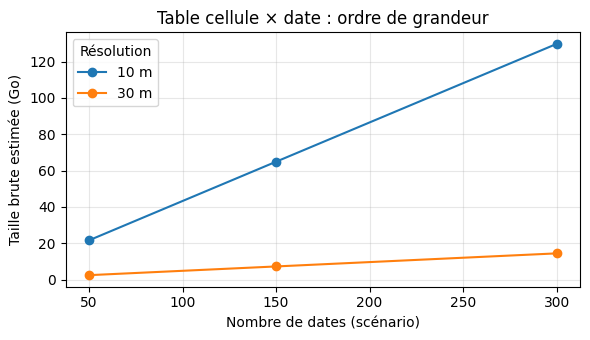

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for res, g in tableau.groupby("résolution (m)"):
    ax.plot(g["dates (scénario)"], g["taille brute (Go)"], marker="o", label=f"{res} m")
ax.set_xlabel("Nombre de dates (scénario)")
ax.set_ylabel("Taille brute estimée (Go)")
ax.set_title("Table cellule × date : ordre de grandeur")
ax.legend(title="Résolution")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
for res, g in tableau.groupby("résolution (m)"):
    print(f"À {res} m : de {g['taille brute (Go)'].min():.1f} à {g['taille brute (Go)'].max():.1f} Go bruts "
          f"selon le scénario de dates (emprise provisoire : {surface_km2:,.0f} km²).")

À 10 m : de 21.6 à 129.8 Go bruts selon le scénario de dates (emprise provisoire : 676 km²).
À 30 m : de 2.4 à 14.4 Go bruts selon le scénario de dates (emprise provisoire : 676 km²).


**Lecture.** Ces tailles sont des **ordres de grandeur bruts** (64 octets par ligne supposés, avant compression Parquet, emprise provisoire). À l'échelle de quelques Go, pandas par morceaux reste possible ; à plusieurs dizaines de Go (résolution fine, nombreuses dates), la mémoire d'un poste personnel est dépassée et Spark devient justifié. Dans tous les cas, le rapport doit dire que **Spark se justifie ici surtout pour les jointures spatiales et l'extension à de plus larges emprises**, et que les calculs raster lourds restent dans Earth Engine.

## 3. Mesures réelles avec Earth Engine *(optionnel)*

Passer `UTILISER_EE = True` après `earthengine authenticate`, et renseigner `PROJET_GEE`. Cette cellule **n'a pas été exécutée** dans l'environnement de génération.

Elle enregistre ses résultats dans `data/raw/verifications_ee.json` comme preuve datée pour la checklist.

In [7]:
UTILISER_EE = False            # passer à True après `earthengine authenticate`
PROJET_GEE = "votre-projet"    # identifiant du projet Google Cloud / Earth Engine

resultats_ee = {}
if UTILISER_EE:
    import ee
    from datetime import date

    ee.Initialize(project=PROJET_GEE)
    aoi = ee.Geometry.Rectangle([lon_min, lat_min, lon_max, lat_max])

    # Bâtiments Open Buildings v3 (identifiant d'après le catalogue Earth Engine ; propriétés à confirmer)
    bati = ee.FeatureCollection("GOOGLE/Research/open-buildings/v3/polygons").filterBounds(aoi)
    resultats_ee["n_batiments_total"] = bati.size().getInfo()
    seuil = cfg["batiments"]["seuil_confiance"]
    resultats_ee["n_batiments_confiance_ok"] = bati.filter(ee.Filter.gte("confidence", seuil)).size().getInfo()

    # Scènes Sentinel-1 (mode IW) par passe, autour de chaque événement daté
    resultats_ee["s1_par_evenement"] = {}
    for e in evts:
        if e["date_pic"] is None:
            continue
        fen = fenetres_evenement(e["date_pic"], cfg["radar"]["fenetre_avant_jours"], cfg["radar"]["fenetre_apres_jours"])
        for nom, (debut, fin) in fen.items():
            col = (ee.ImageCollection("COPERNICUS/S1_GRD").filterBounds(aoi).filterDate(debut, fin)
                   .filter(ee.Filter.eq("instrumentMode", "IW")))
            resultats_ee["s1_par_evenement"][f"{e['id']}_{nom}"] = {
                "fenetre": [debut, fin],
                "scenes_par_passe": col.aggregate_histogram("orbitProperties_pass").getInfo(),
                "dates": sorted({date.fromtimestamp(t / 1000).isoformat()
                                 for t in col.aggregate_array("system:time_start").getInfo()}),
            }
    resultats_ee["date_mesure"] = date.today().isoformat()
    sortie = RACINE / "data" / "raw" / "verifications_ee.json"
    sortie.parent.mkdir(parents=True, exist_ok=True)
    sortie.write_text(json.dumps(resultats_ee, indent=2, ensure_ascii=False), encoding="utf-8")
    print("Enregistré :", sortie)
    print(json.dumps(resultats_ee, indent=2, ensure_ascii=False))
else:
    print("UTILISER_EE = False : aucune mesure réelle effectuée. Les tableaux ci-dessus sont des scénarios.")

UTILISER_EE = False : aucune mesure réelle effectuée. Les tableaux ci-dessus sont des scénarios.


## 4. Ce que ce notebook permet de décider

| Question | Réponse attendue de la section 3 |
|---|---|
| Combien de bâtiments dans l'emprise ? | `n_batiments_total` et `n_batiments_confiance_ok` |
| Les passes ascendante et descendante existent-elles aux dates des événements ? | `scenes_par_passe` par fenêtre |
| Combien de dates radar utilisables ? | `dates` par fenêtre, à comparer aux scénarios de la section 2 |

**Prochaine étape** : `02_etiquettes_radar.ipynb` (calibrer la détection d'eau).